In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

df = pd.read_csv(r"C:\Users\julia\Desktop\Modules\Week5\W5_Day1\amz_uk_price_prediction_dataset.csv")

In [2]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [3]:
#Part 1
#1.1
df_category = pd.DataFrame(df['category'].value_counts())
df_category

,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
...,...
Motorbike Chassis,107
Alexa Built-In Devices,107
Plugs,107


In [4]:
#Part 1
#1.2

df_category_top5 = pd.DataFrame(df['category'].value_counts()).head(5)
df_category_top5

,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


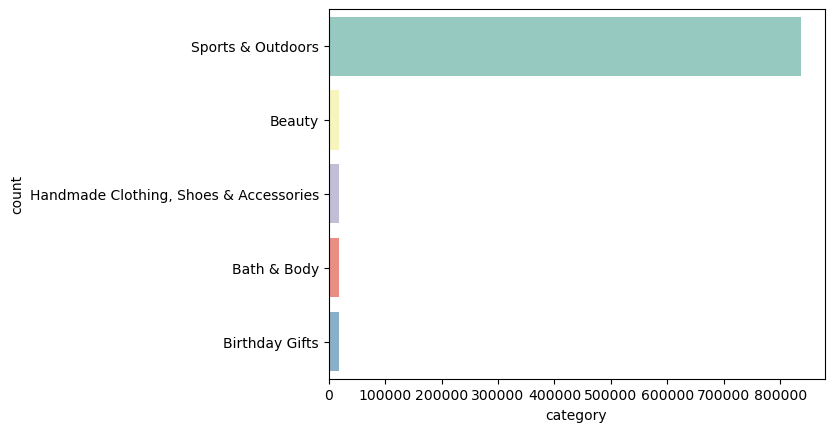

In [5]:
#Part 1
#2.1
fig, axes = plt.subplots()
sns.barplot(x=df_category_top5["count"], y=df_category_top5.index, palette="Set3",hue=df_category_top5.index, legend=False
            ,ax=axes)
axes.set_ylabel("count")
axes.set_xlabel("category")
plt.show()

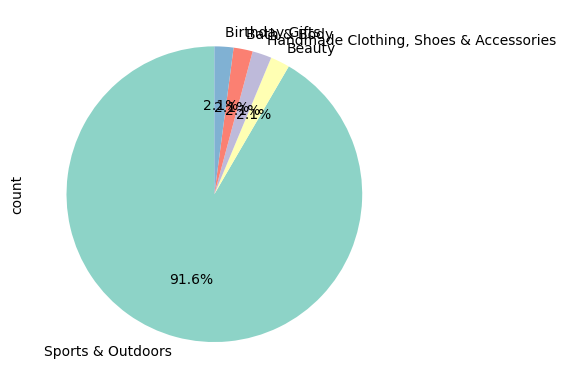

In [6]:
#Part 1
#2.2
df_category_top5["count"].plot.pie(autopct='%.1f%%', startangle=90, colors=sns.color_palette("Set3"));
plt.show()
#Yes, Sports & Outdoors

In [7]:
#Part 2
#1.1
data={"mean": [df['price'].mean()], "median": [df['price'].median()],
 "mode": [df['price'].mode()[0]]}
display(pd.DataFrame(data))

,mean,median,mode
0,89.243809,19.09,9.99


In [8]:
#Part 2
#1.2
print(f"The average of price is {(df['price'].mean()):.2f}, which is much higher than the most common price (mode), which is {df['price'].mode()[0]}.")

The average of price is 89.24, which is much higher than the most common price (mode), which is 9.99.


In [9]:
#Part 2
#2.1
data_2 = {"variance": [df['price'].var()], "maximum": [df['price'].max()], "minimum": [df['price'].min()], "std": [df['price'].std()]}
display(pd.DataFrame(data_2))

,variance,maximum,minimum,std
0,119445.485323,100000.0,0.0,345.608862


In [10]:
#Part 2
#2.2
df_price_quantile = pd.qcut(df['price'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

df_price_quantile.value_counts()

price
Q1    629239
Q3    612341
Q4    609043
Q2    593028
Name: count, dtype: int64

In [11]:
#Part 2
#2.2
# Considering the standard variation, compared to the maximum price, it is a low value, so it seems that there is not a big variation on the prices. Also, if we check the quantiles, the quantity of products does not vary much.

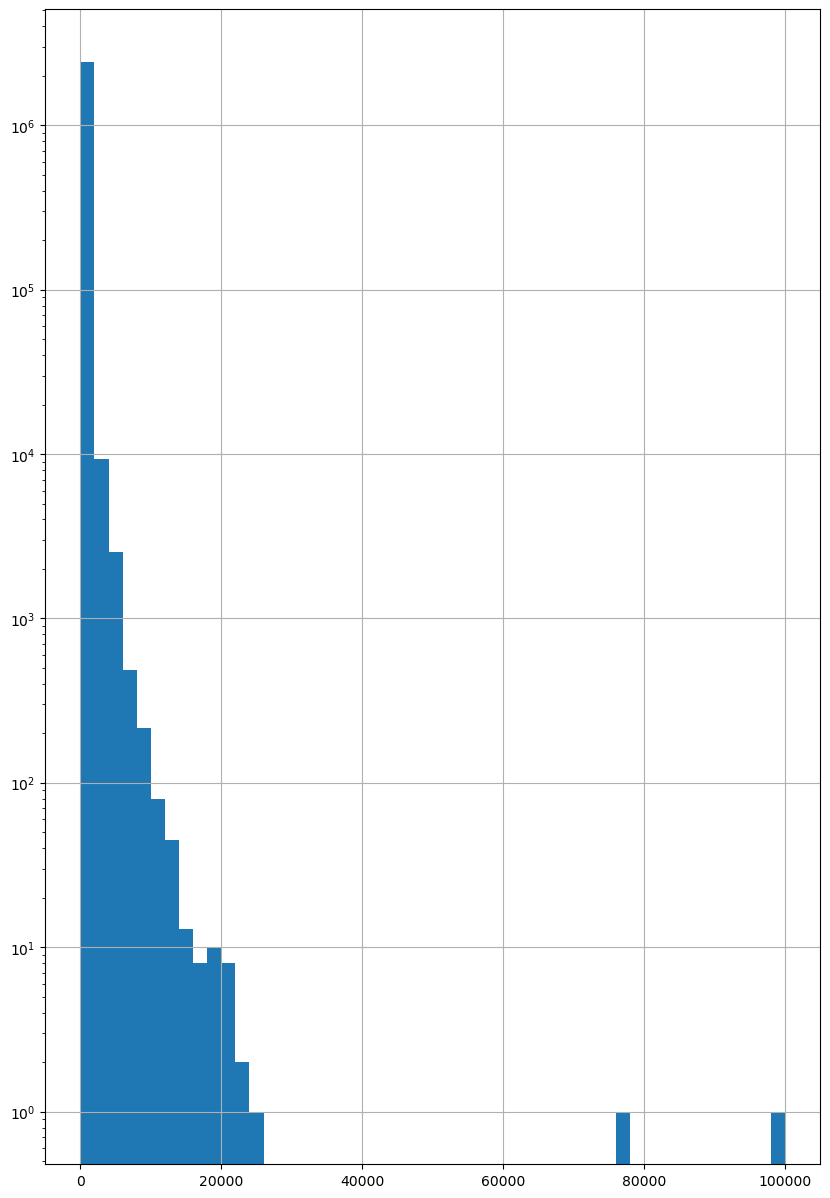

In [12]:
#Part 2
#3.1
df["price"].hist(figsize=(10, 15), bins=50, xlabelsize=10, ylabelsize=10, log=True);
plt.show()
#The great amount of products have prices that fall into the first bar. I used log to make it more comparable.

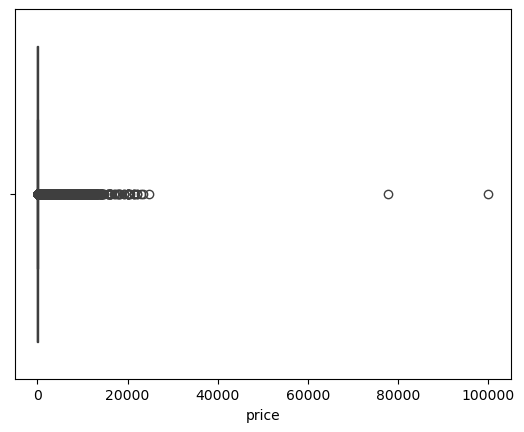

In [13]:
#Part 2
#3.2
sns.boxplot(data=df, x='price');
plt.show()
#Yes, there are, as shown in the chart below. 

In [14]:
#Part 3
#1.1
data_rating = {"mean": [df['stars'].mean()], "median": [df['stars'].median()],
 "mode": [df['stars'].mode()[0]]}
display(pd.DataFrame(data_rating))

,mean,median,mode
0,2.152836,0.0,0.0


In [15]:
#Part 3
#1.2
#Clients most of the time rate products as 0. 

In [16]:
#Part 3
#2.1
data_rating_num = {"variance": [df['stars'].var()], "maximum": [df['stars'].max()], "minimum": [df['stars'].min()], "std": [df['stars'].std()]}
display(pd.DataFrame(data_rating_num))

,variance,maximum,minimum,std
0,4.817434,5.0,0.0,2.194865


In [17]:
#Part 3
#2.1
binned_stars = pd.cut(df['stars'], bins=4, labels=["0%-25%", "25%-50%", "50%-75%", "75%-100%"])

binned_stars.value_counts()

stars
0%-25%      1234151
75%-100%    1095804
50%-75%      103252
25%-50%       10444
Name: count, dtype: int64

In [18]:
df['stars'].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [19]:
#Part 3
#2.2
#There is a wide variation in customer feedback. The ratings are inconsistent. Eighter the ratings are 0 (majority of the ratings, or they are between 4 and 5. The variance and standard deviantion are high. 

In [20]:
#Part 3
#3.1
skewness_ratings = df['stars'].skew()
kurtosis_ratings = df['stars'].kurtosis()

skewness_ratings, kurtosis_ratings

(np.float64(0.08120735761080985), np.float64(-1.9260061280432985))

In [21]:
#Part 3
#3.2
#The skewness is positive, meaning the distribution is right-skewed: most values are on the lower side, but there are a few higher values that stretch the tail to the right.
#The kurtosis is negative, meaning the distribution is flatter than a normal distribution and has lighter tails.

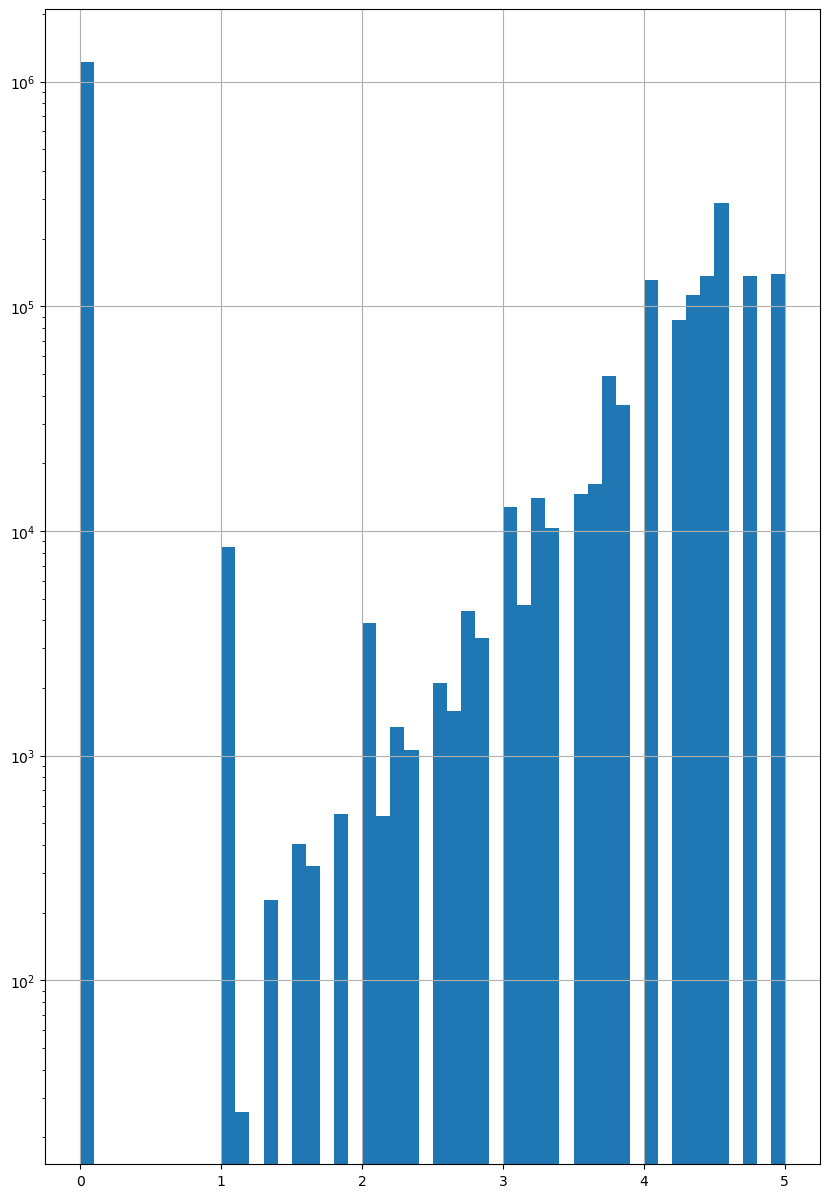

In [23]:
#Part 3
#4: Yes, zero. 
df["stars"].hist(figsize=(10, 15), bins=50, xlabelsize=10, ylabelsize=10, log=True);
plt.show()

In [ ]:
#Business-centric report
#1.Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?
print("The most popular product category on Amazon UK is Sports & Outdoors, which represents 91,6% of the top 5 products.")

In [ ]:
#Business-centric report
#2.Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?
print(f"The average of price is {(df['price'].mean()):.2f}, which is much higher than the most common price (mode), which is {df['price'].mode()[0]}.")
print("Considering the standard variation, compared to the maximum price, it is a low value, so it seems that there is not a big variation on the prices. Also, if we check the quantiles, the quantity of products does not vary much.")
print("However, there are some few products that have extremely high prices compared to the majority of the products.")  

In [24]:
#Business-centric report
#3.Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?
print("Clients most of the time rate products as 0.")
print("There is a wide variation in customer feedback. The ratings are inconsistent. Eighter the ratings are 0 (majority of the ratings), or they are between 4 and 5.")
print("The skewness is positive, meaning the distribution is right-skewed: most values are on the lower side, but there are a few higher values that stretch the tail to the right.")
print("The kurtosis is negative, meaning the distribution is flatter than a normal distribution and has lighter tails.")
print("The most common rate is zero.")

Clients most of the time rate products as 0.
There is a wide variation in customer feedback. The ratings are inconsistent. Eighter the ratings are 0 (majority of the ratings), or they are between 4 and 5.
The skewness is positive, meaning the distribution is right-skewed: most values are on the lower side, but there are a few higher values that stretch the tail to the right.
The kurtosis is negative, meaning the distribution is flatter than a normal distribution and has lighter tails.
The most common rate is zero.
